# Airfoil Self-Noise Prediction Using Machine Learning Regression

## Introduction

Airfoil self-noise is the aerodynamic noise generated when air flows around an airfoil, such as an aircraft wing or turbine blade. The noise produced depends on several aerodynamic factors, including frequency, angle of attack, chord length, free-stream velocity, and suction-side displacement thickness.

Understanding and predicting aerodynamic noise is important in aviation, wind energy, and other engineering applications where noise reduction is a significant consideration.

In this project, the Airfoil Self-Noise dataset obtained from the UCI Machine Learning Repository will be used to develop a Machine Learning regression model that predicts the scaled sound pressure level based on different aerodynamic parameters.

The dataset contains 1,503 observations and six variables, including five independent features and one target variable.

The project follows a complete Machine Learning workflow, beginning with data understanding and cleaning, followed by Exploratory Data Analysis (EDA) to identify patterns, distributions, and relationships between variables.

After exploring the dataset, different regression algorithms will be implemented and trained. Their performance will be evaluated and compared using appropriate regression evaluation metrics, including R² Score, Mean Absolute Error (MAE), and Root Mean Squared Error (RMSE).

Based on the evaluation results, the best-performing model will be selected and used to predict sound pressure levels for previously unseen data.

The main aim of this project is to understand the complete Machine Learning regression process and develop a model capable of making reliable predictions using aerodynamic parameters.


In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

In [2]:

df = pd.read_csv('airfoil_self_noise.dat',
    sep='\t',
    header=None
)

df.columns = [
    'Frequency',
    'Angle_of_Attack',
    'Chord_Length',
    'Free_Stream_Velocity',
    'Suction_Side_Displacement_Thickness',
    'Scaled_Sound_Pressure'
]
print(df)

      Frequency  Angle_of_Attack  Chord_Length  Free_Stream_Velocity  \
0           800              0.0        0.3048                  71.3   
1          1000              0.0        0.3048                  71.3   
2          1250              0.0        0.3048                  71.3   
3          1600              0.0        0.3048                  71.3   
4          2000              0.0        0.3048                  71.3   
...         ...              ...           ...                   ...   
1498       2500             15.6        0.1016                  39.6   
1499       3150             15.6        0.1016                  39.6   
1500       4000             15.6        0.1016                  39.6   
1501       5000             15.6        0.1016                  39.6   
1502       6300             15.6        0.1016                  39.6   

      Suction_Side_Displacement_Thickness  Scaled_Sound_Pressure  
0                                0.002663                126.201  
1

# 1. Data Understanding

Data understanding is the initial stage of the data analysis process. In this stage, we examine the dataset to understand its structure, features, data types, and statistical characteristics.

The Airfoil Self-Noise dataset contains aerodynamic measurements that will be used to predict the scaled sound pressure level.

In this section, we will:

* Examine the dimensions of the dataset (number of rows and columns).
* Identify the column names and their data types.
* Inspect the dataset structure and non-null values.
* Generate descriptive statistical summaries.
* Check for missing values.
* Identify duplicate records.

These steps will help us understand the quality and characteristics of the dataset before proceeding with data cleaning and Exploratory Data Analysis (EDA).


In [9]:
df.shape

(1503, 6)

In [10]:
df.columns

Index(['Frequency', 'Angle_of_Attack', 'Chord_Length', 'Free_Stream_Velocity',
       'Suction_Side_Displacement_Thickness', 'Scaled_Sound_Pressure'],
      dtype='object')

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1503 entries, 0 to 1502
Data columns (total 6 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   Frequency                            1503 non-null   int64  
 1   Angle_of_Attack                      1503 non-null   float64
 2   Chord_Length                         1503 non-null   float64
 3   Free_Stream_Velocity                 1503 non-null   float64
 4   Suction_Side_Displacement_Thickness  1503 non-null   float64
 5   Scaled_Sound_Pressure                1503 non-null   float64
dtypes: float64(5), int64(1)
memory usage: 70.6 KB


In [12]:
df.describe()

,Frequency,Angle_of_Attack,Chord_Length,Free_Stream_Velocity,Suction_Side_Displacement_Thickness,Scaled_Sound_Pressure
count,1503.000000,1503.000000,1503.000000,1503.000000,1503.000000,1503.000000
mean,2886.380572,6.782302,0.136548,50.860745,0.011140,124.835943
std,3152.573137,5.918128,0.093541,15.572784,0.013150,6.898657
min,200.000000,0.000000,0.025400,31.700000,0.000401,103.380000
25%,800.000000,2.000000,0.050800,39.600000,0.002535,120.191000
50%,1600.000000,5.400000,0.101600,39.600000,0.004957,125.721000
75%,4000.000000,9.900000,0.228600,71.300000,0.015576,129.995500
max,20000.000000,22.200000,0.304800,71.300000,0.058411,140.987000


In [13]:
df.isnull().sum()

Frequency                              0
Angle_of_Attack                        0
Chord_Length                           0
Free_Stream_Velocity                   0
Suction_Side_Displacement_Thickness    0
Scaled_Sound_Pressure                  0
dtype: int64

In [14]:
df.duplicated().sum()

0

**Interpretation:**

The dataset contains 1,503 rows and 6 columns. The missing-value check returned zero for all columns, indicating that there are no missing values. Similarly, the duplicate-record check returned 0, confirming that no duplicate rows are present.

Therefore, the dataset does not require missing-value treatment or duplicate removal.


# 2. Data Cleaning

Data cleaning involves examining a dataset to identify inconsistencies, unusual values, missing values, and duplicate records.
Based on the initial data inspection, no missing values or duplicate records were found. Therefore, no missing-value treatment or duplicate removal was necessary.
Further checks were performed to understand the distribution of values and identify potential outliers using descriptive statistics and boxplots.
The identified extreme values were retained because they may represent valid experimental measurements.



In [15]:
df.nunique()

Frequency                                21
Angle_of_Attack                          27
Chord_Length                              6
Free_Stream_Velocity                      4
Suction_Side_Displacement_Thickness     105
Scaled_Sound_Pressure                  1456
dtype: int64

In [16]:
df.agg(['min', 'max'])

,Frequency,Angle_of_Attack,Chord_Length,Free_Stream_Velocity,Suction_Side_Displacement_Thickness,Scaled_Sound_Pressure
min,200,0.0,0.0254,31.7,0.000401,103.380
max,20000,22.2,0.3048,71.3,0.058411,140.987


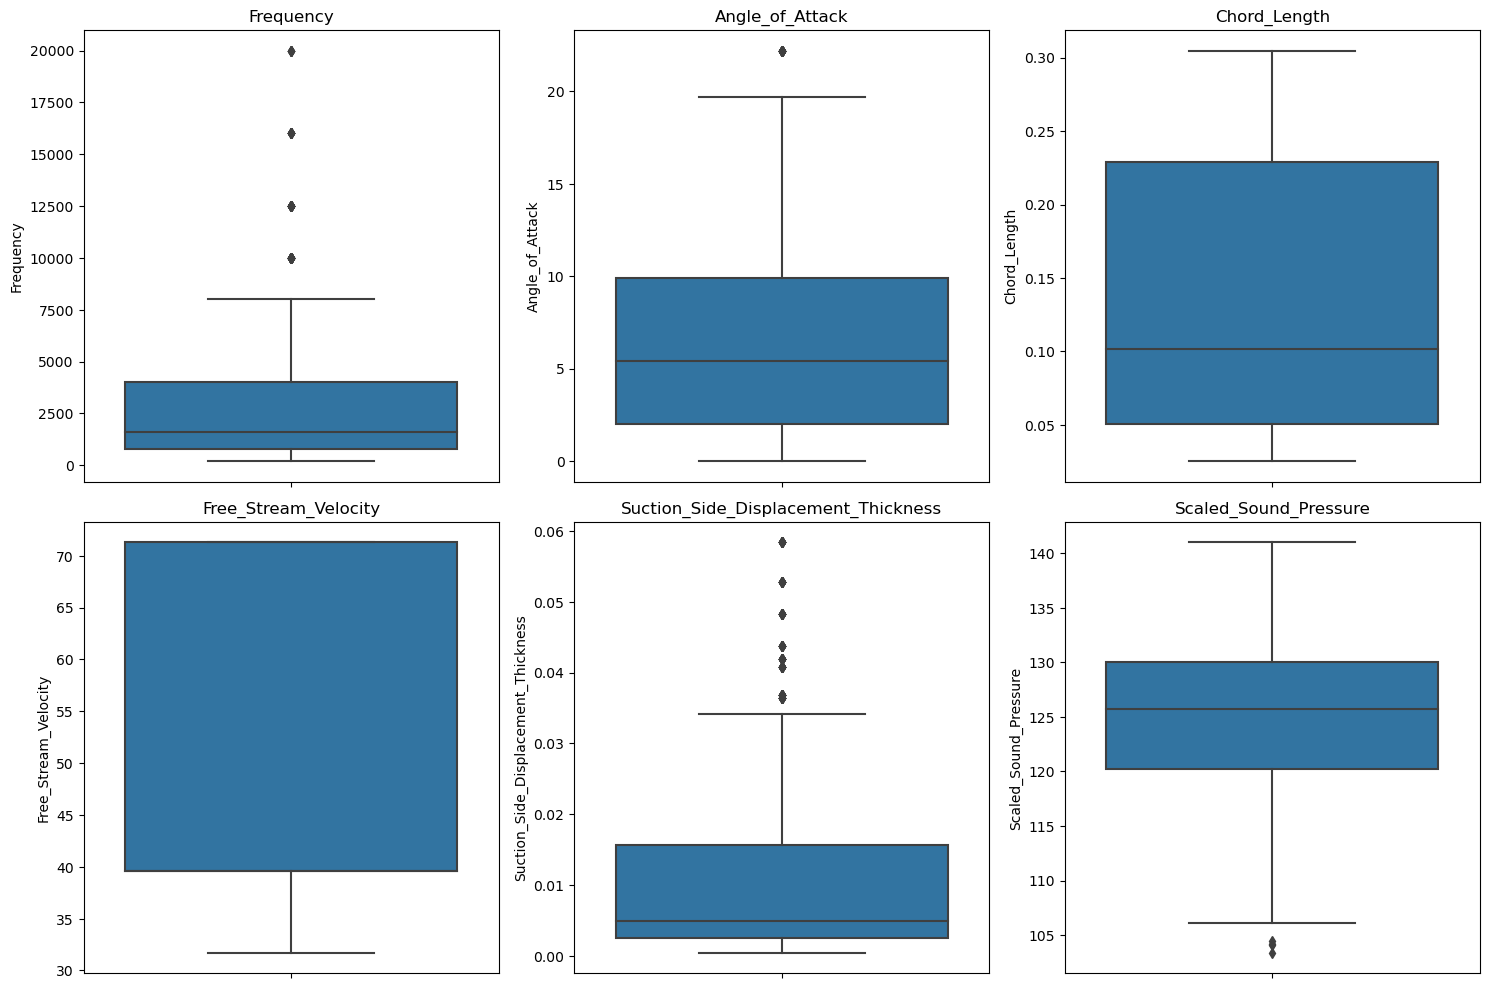

In [17]:
plt.figure(figsize=(15, 10))

for i, column in enumerate(df.columns, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(y=df[column])
    plt.title(column)

plt.tight_layout()
plt.show()

**Interpretation:**

The boxplots indicate potential outliers in Frequency, Angle of Attack, Suction Side Displacement Thickness, and Scaled Sound Pressure. Chord Length and Free Stream Velocity show no apparent outliers.

These extreme values may represent valid experimental measurements, so they will be retained rather than removed without further justification.


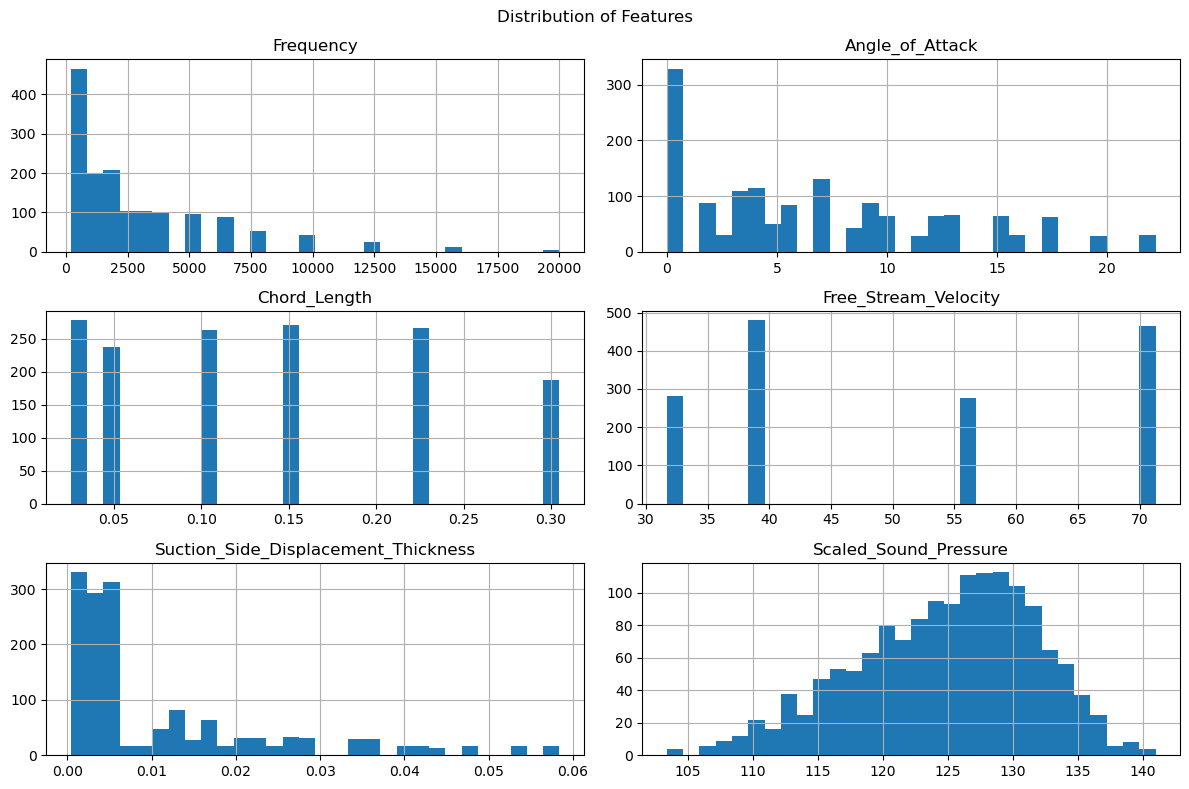

In [20]:
df.hist(figsize=(12, 8), bins=30)

plt.suptitle('Distribution of Features')

plt.tight_layout()
plt.show()

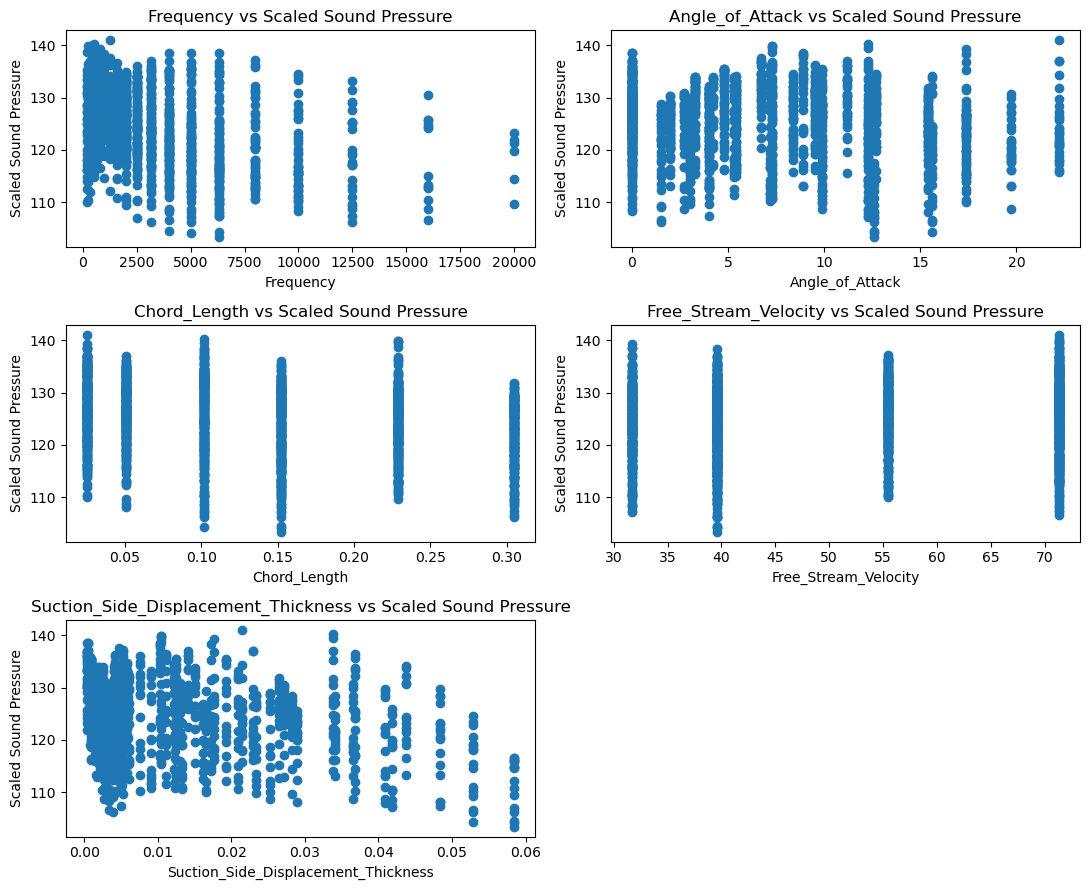

In [23]:
features = ['Frequency', 'Angle_of_Attack', 'Chord_Length',
            'Free_Stream_Velocity',
            'Suction_Side_Displacement_Thickness']

plt.figure(figsize=(11, 9))

for i, feature in enumerate(features, 1):
    plt.subplot(3, 2, i)
    plt.scatter(df[feature], df['Scaled_Sound_Pressure'])
    plt.xlabel(feature)
    plt.ylabel('Scaled Sound Pressure')
    plt.title(f'{feature} vs Scaled Sound Pressure')

plt.tight_layout()
plt.show()

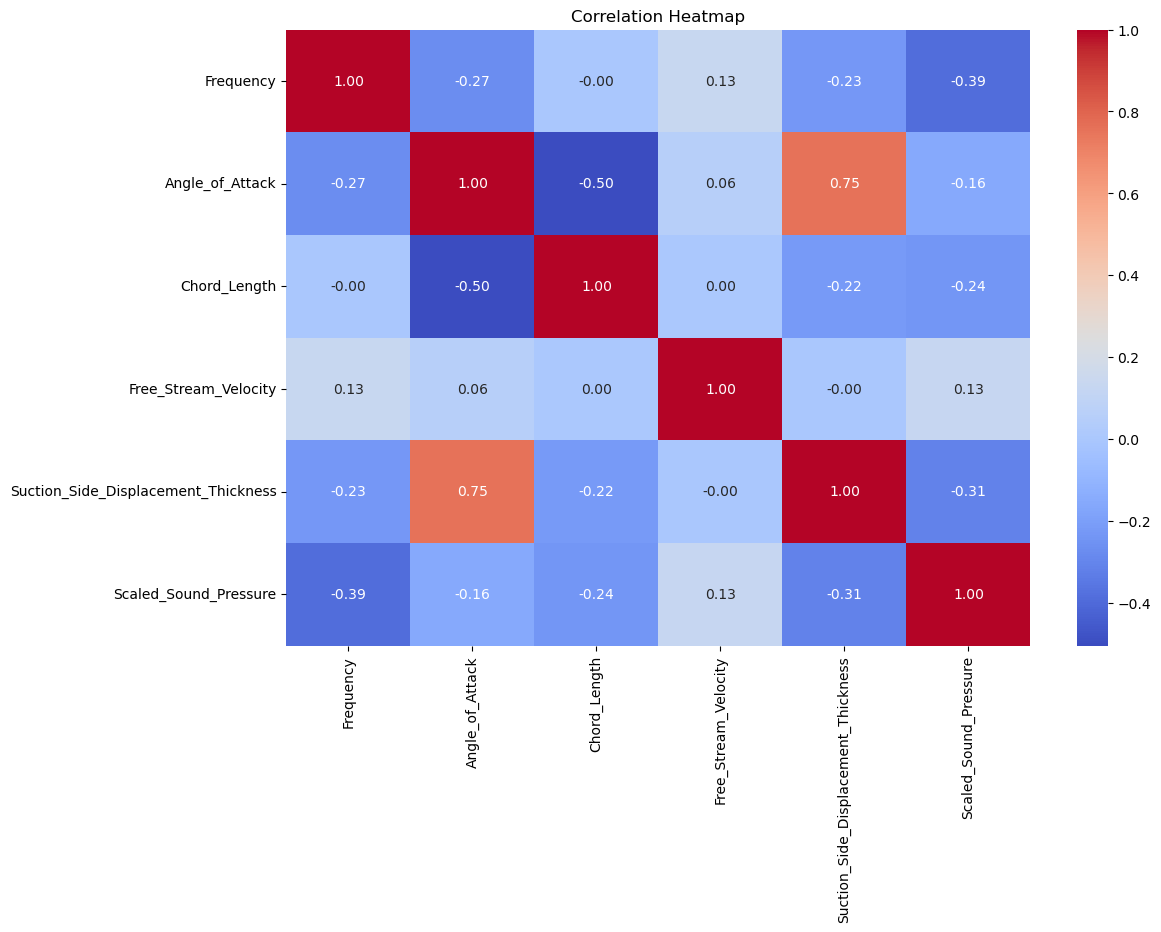

In [19]:
correlation = df.corr()
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()

### Correlation Heatmap

A correlation heatmap was created to understand the strength and direction of linear relationships between the numerical variables.

**Observations:**

* Frequency has the strongest negative correlation with Scaled Sound Pressure (-0.39).
* Suction Side Displacement Thickness has a negative correlation of -0.31 with the target.
* Free Stream Velocity has a weak positive correlation of +0.13 with the target.
* Angle of Attack and Suction Side Displacement Thickness show a strong positive correlation of +0.75.

**Conclusion:**

The heatmap provides an overview of the relationships between input features and the target variable. These relationships will be useful when developing and evaluating regression models.


In [3]:
X = df.iloc[:, :-1].values
y = df.iloc[:, 5].values

In [4]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [5]:
from sklearn.preprocessing import StandardScaler

sc = StandardScaler()

X_train_scaled = sc.fit_transform(X_train)

X_test_scaled = sc.transform(X_test)

In [6]:
from sklearn.linear_model import LinearRegression
from sklearn import metrics
from sklearn.metrics import r2_score
import numpy as np

# Create the model
regressor = LinearRegression()

# Train the model
regressor.fit(X_train_scaled, y_train)

# Predict
y_pred_lr = regressor.predict(X_test_scaled)

# Evaluate the model
print('Mean Absolute Error:',
      metrics.mean_absolute_error(y_test, y_pred_lr))

print('Mean Squared Error:',
      metrics.mean_squared_error(y_test, y_pred_lr))

print('Root Mean Squared Error:',
      np.sqrt(metrics.mean_squared_error(y_test, y_pred_lr)))

score = r2_score(y_test, y_pred_lr)

print('R2 Score:', score * 100, '%')

Mean Absolute Error: 3.6724145641788013
Mean Squared Error: 22.12864331824728
Root Mean Squared Error: 4.704109194974887
R2 Score: 55.829797548972834 %


In [7]:
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
# Create polynomial features
poly = PolynomialFeatures(degree=2)

X_train_poly = poly.fit_transform(X_train_scaled)
X_test_poly = poly.transform(X_test_scaled)

# Create and train model
regressor_poly = LinearRegression()
regressor_poly.fit(X_train_poly, y_train)

# Predict
y_pred_poly = regressor_poly.predict(X_test_poly)

# Evaluate
print('MAE:', metrics.mean_absolute_error(y_test, y_pred_poly))
print('MSE:', metrics.mean_squared_error(y_test, y_pred_poly))
print('RMSE:', np.sqrt(metrics.mean_squared_error(y_test, y_pred_poly)))

score = r2_score(y_test, y_pred_poly)
print('R2 Score:', score * 100, '%')

MAE: 3.04751870168777
MSE: 15.828208741777887
RMSE: 3.978468140098383
R2 Score: 68.40587222150486 %


In [8]:
from sklearn.tree import DecisionTreeRegressor
# Create the model
regressor_dt = DecisionTreeRegressor(random_state=42)

# Train the model
regressor_dt.fit(X_train, y_train)

# Predict
y_pred_dt = regressor_dt.predict(X_test)

# Evaluate the model
print('Mean Absolute Error:',
      metrics.mean_absolute_error(y_test, y_pred_dt))

print('Mean Squared Error:',
      metrics.mean_squared_error(y_test, y_pred_dt))

print('Root Mean Squared Error:',
      np.sqrt(metrics.mean_squared_error(y_test, y_pred_dt)))

score = r2_score(y_test, y_pred_dt)
print('R2 Score:', score * 100, '%')

Mean Absolute Error: 1.7340066445182718
Mean Squared Error: 5.876174498338868
Root Mean Squared Error: 2.424082197108602
R2 Score: 88.27077586744035 %


In [9]:
from sklearn.ensemble import RandomForestRegressor
# Create the model
regressor_rf = RandomForestRegressor(n_estimators=100, random_state=42)

# Train the model
regressor_rf.fit(X_train, y_train)

# Predict
y_pred_rf = regressor_rf.predict(X_test)

# Evaluate the model
print('Mean Absolute Error:',
      metrics.mean_absolute_error(y_test, y_pred_rf))

print('Mean Squared Error:',
      metrics.mean_squared_error(y_test, y_pred_rf))

print('Root Mean Squared Error:',
      np.sqrt(metrics.mean_squared_error(y_test, y_pred_rf)))

score = r2_score(y_test, y_pred_rf)
print('R2 Score:', score * 100, '%')

Mean Absolute Error: 1.3119336877076426
Mean Squared Error: 3.2787235884199353
Root Mean Squared Error: 1.8107246031409456
R2 Score: 93.45545578196172 %


In [10]:
from sklearn.svm import SVR
# Create the model
regressor_svr = SVR()

# Train the model
regressor_svr.fit(X_train_scaled, y_train)

# Predict
y_pred_svr = regressor_svr.predict(X_test_scaled)

# Evaluate the model
print('Mean Absolute Error:',
      metrics.mean_absolute_error(y_test, y_pred_svr))

print('Mean Squared Error:',
      metrics.mean_squared_error(y_test, y_pred_svr))

print('Root Mean Squared Error:',
      np.sqrt(metrics.mean_squared_error(y_test, y_pred_svr)))

score = r2_score(y_test, y_pred_svr)
print('R2 Score:', score * 100, '%')

Mean Absolute Error: 2.8315718192268347
Mean Squared Error: 13.84820504655189
Root Mean Squared Error: 3.7213176492409095
R2 Score: 72.35808758392598 %


In [11]:
from sklearn.neighbors import KNeighborsRegressor
# Create the model
regressor_knn = KNeighborsRegressor(n_neighbors=5)

# Train the model
regressor_knn.fit(X_train_scaled, y_train)

# Predict
y_pred_knn = regressor_knn.predict(X_test_scaled)

# Evaluate the model
print('Mean Absolute Error:',
      metrics.mean_absolute_error(y_test, y_pred_knn))

print('Mean Squared Error:',
      metrics.mean_squared_error(y_test, y_pred_knn))

print('Root Mean Squared Error:',
      np.sqrt(metrics.mean_squared_error(y_test, y_pred_knn)))

score = r2_score(y_test, y_pred_knn)
print('R2 Score:', score * 100, '%')

Mean Absolute Error: 2.417124916943522
Mean Squared Error: 10.885640956411965
Root Mean Squared Error: 3.2993394727448044
R2 Score: 78.27155700695738 %


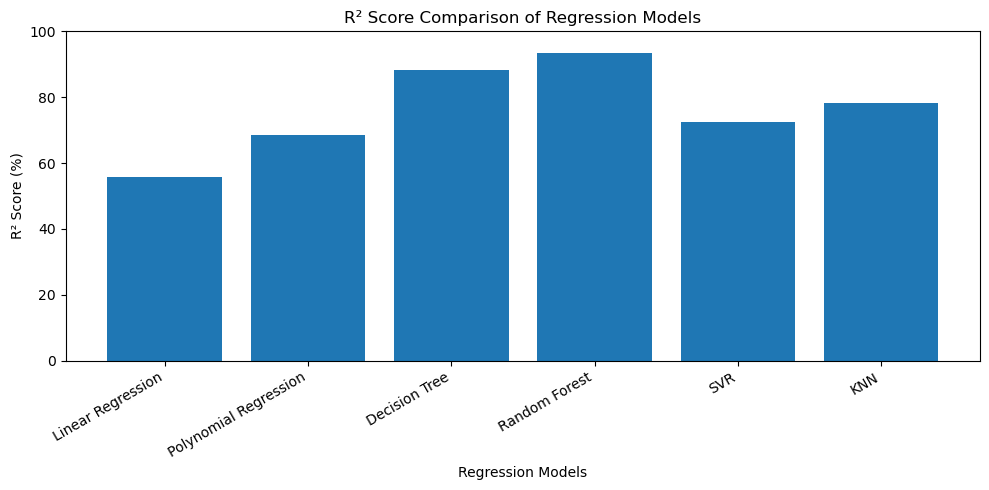

In [12]:
models = ['Linear Regression', 'Polynomial Regression',
          'Decision Tree', 'Random Forest', 'SVR', 'KNN']

r2_scores = [55.83, 68.41, 88.27, 93.46, 72.36, 78.27]

plt.figure(figsize=(10, 5))

plt.bar(models, r2_scores)

plt.title('R² Score Comparison of Regression Models')
plt.xlabel('Regression Models')
plt.ylabel('R² Score (%)')

plt.ylim(0, 100)
plt.xticks(rotation=30, ha='right')

plt.tight_layout()
plt.show()

Interpretation

Random Forest Regression achieved the highest R² score of 93.46%, followed by Decision Tree Regression (88.27%). Linear Regression had the lowest score of 55.83%. This indicates that Random Forest Regression provided the best fit among the six models evaluated.

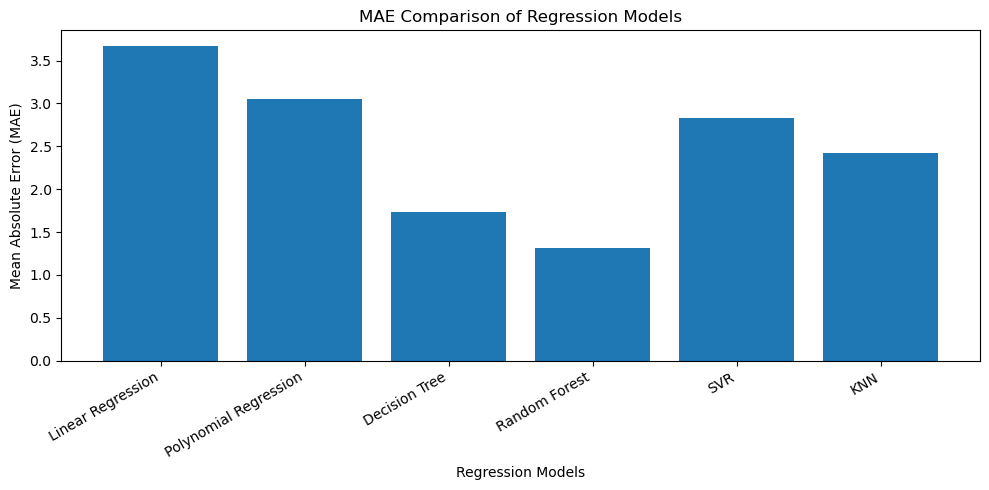

In [13]:
mae_scores = [3.67, 3.05, 1.73, 1.31, 2.83, 2.42]

plt.figure(figsize=(10, 5))

plt.bar(models, mae_scores)

plt.title('MAE Comparison of Regression Models')
plt.xlabel('Regression Models')
plt.ylabel('Mean Absolute Error (MAE)')

plt.xticks(rotation=30, ha='right')

plt.tight_layout()
plt.show()

Interpretation

Random Forest Regression achieved the lowest MAE of 1.31 dB, indicating the smallest average prediction error among the six models. Linear Regression had the highest MAE of 3.67 dB. Therefore, Random Forest Regression provided the most accurate predictions based on MAE.
 Lower MAE indicates better prediction performance.

In [14]:
comparison = pd.DataFrame({
    'Model': ['Linear Regression', 'Polynomial Regression',
              'Decision Tree', 'Random Forest', 'SVR', 'KNN'],

    'MAE': [3.67, 3.05, 1.73, 1.31, 2.83, 2.42],

    'MSE': [22.13, 15.83, 5.88, 3.28, 13.85, 10.89],

    'RMSE': [4.70, 3.98, 2.42, 1.81, 3.72, 3.30],

    'R2 Score (%)': [55.83, 68.41, 88.27, 93.46, 72.36, 78.27]
})

comparison

,Model,MAE,MSE,RMSE,R2 Score (%)
0,Linear Regression,3.67,22.13,4.70,55.83
1,Polynomial Regression,3.05,15.83,3.98,68.41
2,Decision Tree,1.73,5.88,2.42,88.27
3,Random Forest,1.31,3.28,1.81,93.46
4,SVR,2.83,13.85,3.72,72.36
5,KNN,2.42,10.89,3.30,78.27


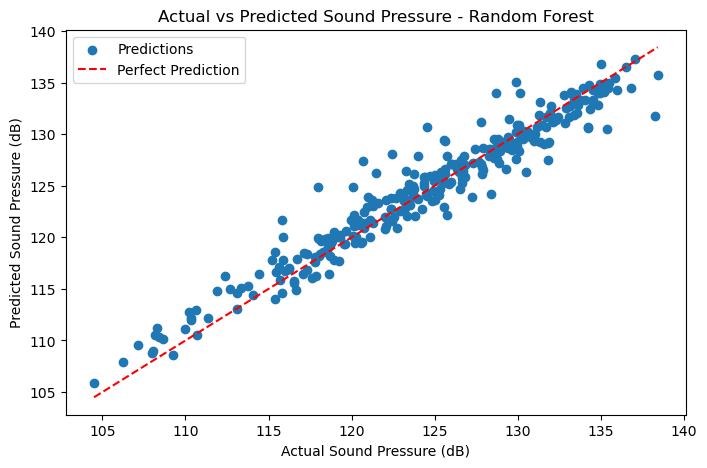

In [19]:
plt.figure(figsize=(8, 5))

# Actual vs Predicted scatter plot
plt.scatter(y_test, y_pred_rf, label='Predictions')

# Add diagonal reference line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--',
    label='Perfect Prediction'
)

plt.xlabel('Actual Sound Pressure (dB)')
plt.ylabel('Predicted Sound Pressure (dB)')

plt.title('Actual vs Predicted Sound Pressure - Random Forest')

plt.legend()
plt.show()

### Interpretation

Most data points are close to the diagonal reference line, indicating that the predicted sound pressure values are close to the actual values. This suggests that the Random Forest model provides good prediction performance.



In [16]:
new_data = [[1000, 5.4, 0.1524, 71.3, 0.0007]]
prediction = regressor_rf.predict(new_data)

print("Predicted Sound Pressure:", prediction[0], "dB")

Predicted Sound Pressure: 131.29174999999984 dB


                               Feature  Importance
0                            Frequency    0.416394
4  Suction_Side_Displacement_Thickness    0.406471
2                         Chord_Length    0.093132
1                      Angle_of_Attack    0.042195
3                 Free_Stream_Velocity    0.041809


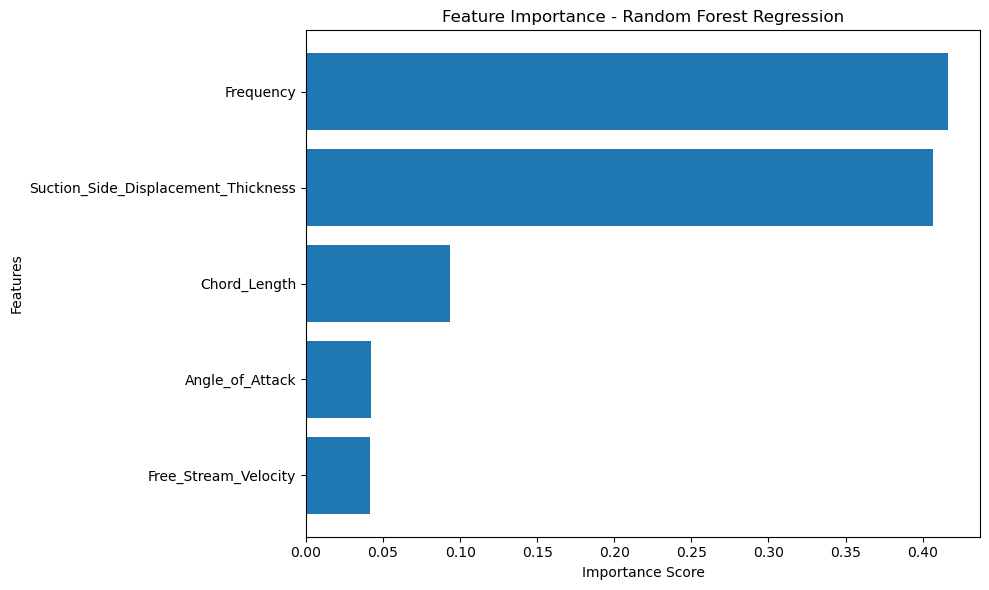

In [18]:
# Get feature names
feature_names = df.columns[:-1]

# Get feature importance from Random Forest
importances = regressor_rf.feature_importances_

# Create a DataFrame
feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
})

# Sort features by importance
feature_importance_df = feature_importance_df.sort_values(
    by='Importance', ascending=False
)

print(feature_importance_df)



plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance_df['Feature'],
    feature_importance_df['Importance']
)

plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.title('Feature Importance - Random Forest Regression')

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

Interpretation

Frequency (41.64%) and Suction Side Displacement Thickness (40.65%) have the highest importance scores in the Random Forest model, together contributing approximately 82.29% of the total feature importance. The remaining features have relatively lower importance scores.

## Key Findings

1. **Dataset Quality:** The dataset contained 1,503 observations and 6 columns, including five input features and one target variable. No missing values or duplicate records were found during data inspection.

2. **Model Performance:** Six regression algorithms were evaluated: Linear Regression, Polynomial Regression, Decision Tree, Random Forest, Support Vector Regression (SVR), and K-Nearest Neighbors (KNN). Among them, Random Forest Regression achieved the best performance, with an R² score of 93.46% and a Mean Absolute Error (MAE) of approximately 1.31 dB.

3. **Non-Linear Relationships:** Polynomial Regression performed better than Linear Regression, indicating that the relationship between the input features and sound pressure may involve non-linear patterns.

4. **Tree-Based Model Performance:** Decision Tree and Random Forest Regression performed better than the other evaluated algorithms. Random Forest achieved the lowest prediction errors among all six models.

5. **Feature Importance:** According to the Random Forest feature importance analysis, Frequency (41.64%) and Suction Side Displacement Thickness (40.65%) received the highest importance scores. Together, they accounted for approximately 82.29% of the model's total feature importance.

6. **Prediction Results:** The actual-versus-predicted visualization showed that most Random Forest predictions were close to the actual sound pressure values. The selected model was also used to predict sound pressure for a new sample, producing a predicted value of approximately 131.29 dB.

7. **Overall Observation:** The comparison demonstrated that different regression algorithms produce different results on the same dataset. Based on the evaluated performance metrics, Random Forest Regression was the most suitable model among the six algorithms tested in this project.


### Limitations


1. **Limited Dataset Size:** The project uses 1,503 observations. A larger dataset could help the model learn more patterns and improve its ability to generalize.

2. **Limited Features:** The prediction is based on only five input features: Frequency, Angle of Attack, Chord Length, Free Stream Velocity, and Suction Side Displacement Thickness. Other factors that may influence airfoil noise are not included.

3. **Dataset Dependency:** The model is trained using experimental airfoil self-noise data. Its performance on different airfoil designs or real-world operating conditions may vary.

4. **Limited Model Optimization:** The regression models were trained using their selected initial parameters. Extensive hyperparameter tuning was not performed, so further optimization may improve performance.

5. **Limited Evaluation:** The models were evaluated using a single train-test split. Testing with cross-validation and additional datasets would provide a more comprehensive understanding of their performance.


## Conclusion

This project focuses on predicting scaled sound pressure levels generated by airfoils using Machine Learning regression techniques.

The Airfoil Self-Noise dataset was used to study the relationship between five aerodynamic input features and sound pressure levels. The dataset was examined through data understanding, data cleaning, and exploratory data analysis.

After preparing the data through feature selection, train-test splitting, and feature scaling, six regression algorithms were implemented:

* Linear Regression
* Polynomial Regression
* Decision Tree Regression
* Random Forest Regression
* Support Vector Regression
* K-Nearest Neighbors Regression

The models were evaluated using Mean Absolute Error (MAE), Mean Squared Error (MSE), Root Mean Squared Error (RMSE), and R² Score.

Among the six models, Random Forest Regression achieved the best performance, with an R² score of approximately **93.46%** and an MAE of approximately **1.31 dB** on the test dataset.

The actual versus predicted visualization showed that most predictions were close to the actual sound pressure values. Feature importance analysis also helped identify the input features that contributed most to the model's predictions.

Finally, the selected model was used to predict sound pressure for new input data.

Overall, this project demonstrates how Machine Learning regression techniques can be used to predict airfoil self-noise and how comparing different algorithms helps identify a suitable model for a prediction task.
